In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

from pathlib import Path

In [4]:
# dataset path and structure
DATA_DIR = Path("../data/zenodo_v2/")

for file in sorted(DATA_DIR.iterdir()):
    print(file.name)

LICENSE-DATA
README.md
case_matrix.csv
cz_v2_doe.zip
cz_v2_holdout.zip
cz_v2_mesh_coarse.zip
cz_v2_mesh_fine.zip
doe_excluded_cases.csv
doe_run_status.csv
holdout_cases.csv
holdout_excluded_cases.csv
holdout_run_status.csv
mesh_study_fields.csv
mesh_study_quantities.csv
node_order_base_8181.csv
node_order_coarse_2091.csv
node_order_fine_32200.csv


In [5]:
# Read the case matrix
cases = pd.read_csv(DATA_DIR / "case_matrix.csv")

cases.head()

,case_id,group,crystal_rpm,crucible_rpm,t_hot
0,sobol_000,sobol,10.896472,-2.670688,1774.352702
1,sobol_001,sobol,17.917017,-6.062550,1757.430408
2,sobol_002,sobol,13.246647,-5.408550,1769.955855
3,sobol_003,sobol,6.189864,-7.851605,1731.750599
4,sobol_004,sobol,4.694309,-3.565196,1749.589687


In [6]:
 # Basic metadata inspectionn

print("Shape:", cases.shape)
print("\nData types:")
print(cases.dtypes)

print("\nCase groups:")
print(cases["group"].value_counts())

Shape: (265, 5)

Data types:
case_id             str
group               str
crystal_rpm     float64
crucible_rpm    float64
t_hot           float64
dtype: object

Case groups:
group
sobol     256
corner      8
centre      1
Name: count, dtype: int64


In [8]:
# inspect simulation status

status = pd.read_csv(DATA_DIR / "doe_run_status.csv")

print(status["status"].value_counts())

status
kept        254
excluded     11
Name: count, dtype: int64


In [9]:
# Inspecct Zip archieve

import zipfile

DOE_ZIP = DATA_DIR / "cz_v2_doe.zip"

with zipfile.ZipFile(DOE_ZIP, 'r') as archive:
    csv_files = [
        name for name in archive.namelist()
        if name.endswith('.csv')
    ]

print("Number of simulations:", len(csv_files))
print("First 10 files:", csv_files[:10])

Number of simulations: 254
First 10 files: ['doe/centre_000.csv', 'doe/corner_000.csv', 'doe/corner_001.csv', 'doe/corner_002.csv', 'doe/corner_003.csv', 'doe/corner_004.csv', 'doe/corner_005.csv', 'doe/corner_006.csv', 'doe/corner_007.csv', 'doe/sobol_000.csv']


In [10]:
# Load a single simulation case

case_id = "sobol_000"

with zipfile.ZipFile(DOE_ZIP, 'r') as archive:
    with archive.open(f"doe/{case_id}.csv") as file:
        df = pd.read_csv(file)

df.head()

,r,z,u_r,u_z,u_swirl,p,T
0,0.0,0.000000,0.000000e+00,0.000000e+00,-0.000080,0.000000,1700.234504
1,0.0,0.000358,-7.902644e-08,-1.058307e-07,-0.000080,-0.011836,1700.562211
2,0.0,0.000741,-1.950697e-07,6.806566e-07,-0.000079,-0.034572,1701.018623
3,0.0,0.001152,-3.537789e-07,1.332536e-06,-0.000078,-0.056055,1701.456918
4,0.0,0.001592,-5.581510e-07,2.712404e-06,-0.000077,-0.078243,1701.886610


In [11]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (8181, 7)
Columns: ['r', 'z', 'u_r', 'u_z', 'u_swirl', 'p', 'T']


In [12]:
# Match simulation with its metadata

case_info = cases.loc[cases["case_id"] == case_id]

case_info

,case_id,group,crystal_rpm,crucible_rpm,t_hot
0,sobol_000,sobol,10.896472,-2.670688,1774.352702


In [13]:
# Chec kNumerical  validity

print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nAll values finite:")
print(np.isfinite(df.to_numpy()).all())

print("\nDuplicate spatial coordinates:")
print(df[["r", "z"]].duplicated().sum())

Data types:
r          float64
z          float64
u_r        float64
u_z        float64
u_swirl    float64
p          float64
T          float64
dtype: object

Missing values:
r          0
z          0
u_r        0
u_z        0
u_swirl    0
p          0
T          0
dtype: int64

All values finite:
True

Duplicate spatial coordinates:
0


In [14]:
# Statistical description

df.describe().T

,count,mean,std,min,25%,50%,75%,max
r,8181.0,0.150407,0.113197,0.000000,0.030165,0.151017,0.271148,0.300000
z,8181.0,0.075000,0.057043,0.000000,0.014971,0.075000,0.135029,0.150000
u_r,8181.0,0.000773,0.004476,-0.011379,-0.000740,0.000000,0.001626,0.018476
u_z,8181.0,0.001758,0.004312,-0.012927,0.000002,0.000302,0.002547,0.015990
u_swirl,8181.0,-0.007196,0.061036,-0.083902,-0.062145,-0.003956,0.012043,0.201479
p,8181.0,3.250876,6.034406,-2.933419,-0.793223,-0.005862,5.023168,19.414504
T,8181.0,1731.684882,27.272602,1685.000000,1711.728436,1720.467241,1759.771047,1774.352702


In [87]:
# Separate data into arrays

coordinate_columns = ["r", "z"]

field_columns = ["u_r", "u_z", "u_swirl", "p", "T"]

parameter_columns = [
    "crystal_rpm",
    "crucible_rpm",
    "t_hot"
]

pos = df[coordinate_columns].to_numpy()
y = df[field_columns].to_numpy()

mu = case_info[parameter_columns].to_numpy()[0]

print("Coordinates:", pos.shape)
print("Field values:", y.shape)
print("Operating Parameters:", mu.shape)

Coordinates: (8181, 2)
Field values: (8181, 5)
Operating Parameters: (3,)


In [16]:
# Comparing the spatial distribution of the field values

reference = pd.read_csv(
    DATA_DIR / "node_order_base_8181.csv"
)

reference_pos = reference[["r", "z"]].to_numpy()

print("Reference Shape:", reference_pos.shape)
print("Identical coordinnates:", np.array_equal(pos, reference_pos))
print("Maximum coodinate difference", np.max(np.abs(pos - reference_pos)))

Reference Shape: (8181, 2)
Identical coordinnates: True
Maximum coodinate difference 0.0


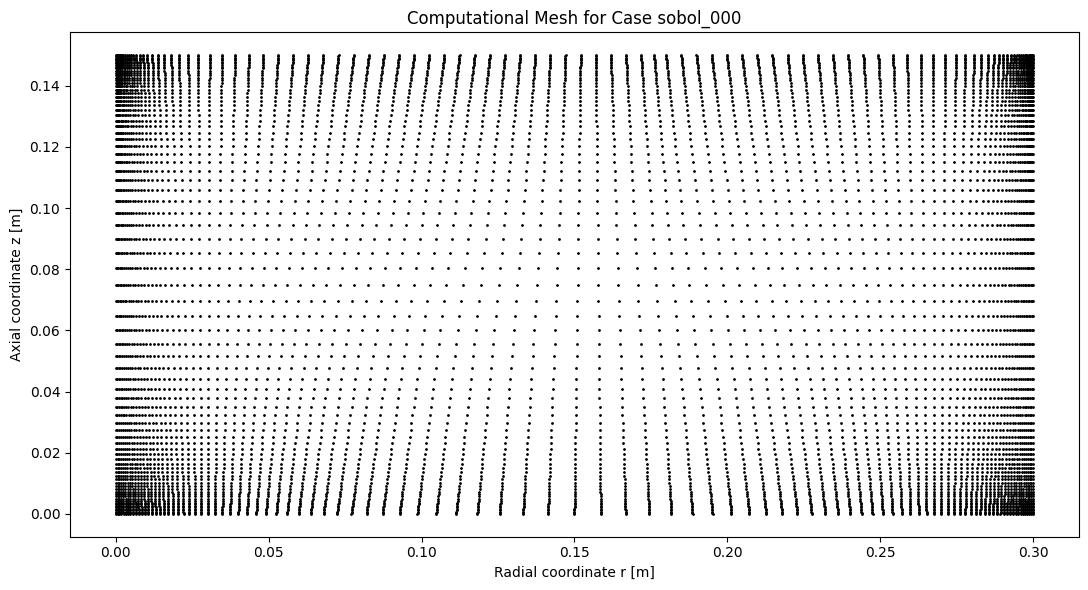

In [17]:
# Plots the meshes and nodes

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(df["r"], df["z"], s=1, color="black")
ax.set_xlabel("Radial coordinate r [m]")
ax.set_ylabel("Axial coordinate z [m]")
ax.set_title(f"Computational Mesh for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [18]:
 # Investigate the mesh arrangement

print("Total nodes:",  len(df))
print("Uniques radial coordinates:", df["r"].nunique())
print("Uniques axial coordinates:", df["z"].nunique())  

nodes_per_level = df.groupby("z").size()

print("\nNodes per axial level:")
print(nodes_per_level.value_counts())

Total nodes: 8181
Uniques radial coordinates: 8021
Uniques axial coordinates: 81

Nodes per axial level:
101    81
Name: count, dtype: int64


In [20]:
# Create the logical grid

df_grid = df.sort_values(
    ["z", "r"]
).reset_index(drop=True)

nz = df["z"].nunique()
nr = int(nodes_per_level.iloc[0])

assert (nodes_per_level == nr).all()
assert nr * nz == len(df)

R = df_grid["r"].to_numpy().reshape(nz, nr)
Z = df_grid["z"].to_numpy().reshape(nz, nr)

print("R shape:", R.shape)
print("Z shape:", Z.shape)

R shape: (81, 101)
Z shape: (81, 101)


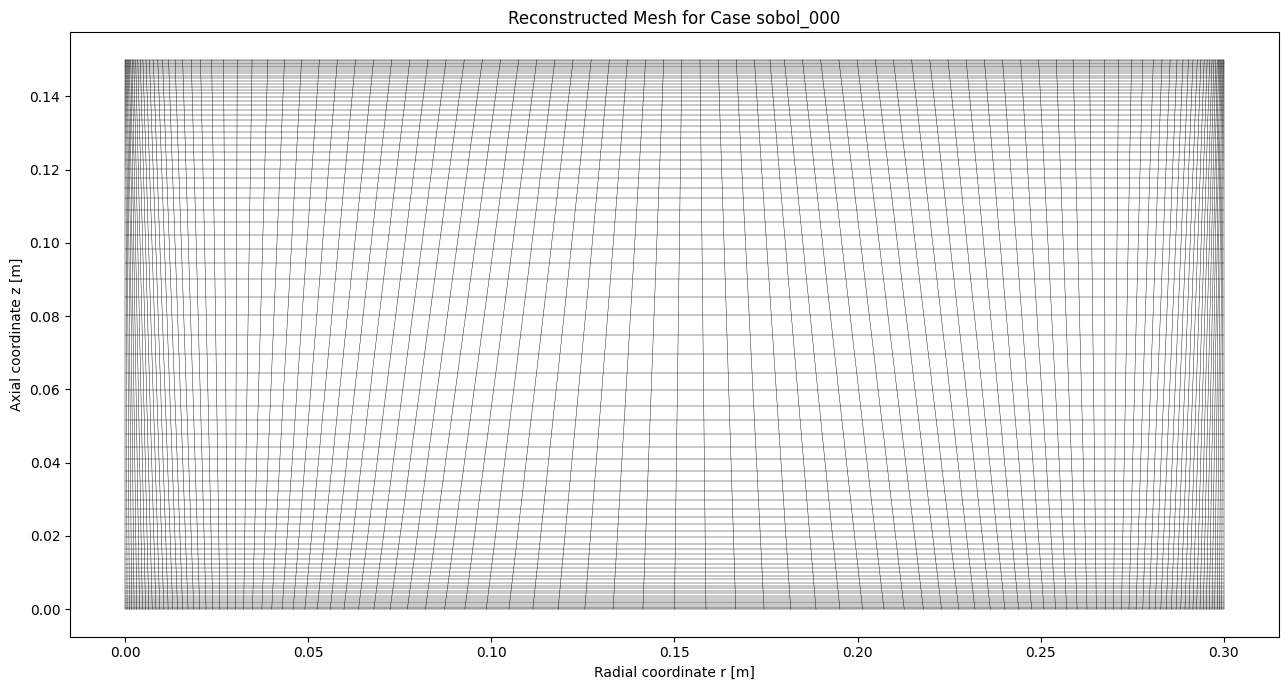

In [23]:
# visualize the reconstructed mesh

fig, ax = plt.subplots(figsize=(14, 7))

# Connect nodes along the radial direction
ax.plot(R.T, Z.T, color="black", linewidth=0.3)

# Connect nodes along the axial direction
ax.plot(R, Z, color="black", linewidth=0.3)

ax.set_xlabel("Radial coordinate r [m]")
ax.set_ylabel("Axial coordinate z [m]")
ax.set_title(f"Reconstructed Mesh for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [24]:
# Calculate mesh spacing

dr = np.diff(R, axis=1)
dz = np.diff(Z, axis=0)

print("minimum dr:", dr.min() )
print("maximum dr:", dr.max() )

print("minimum dz:", dz.min() )
print("maximum dz:", dz.max() )

minimum dr: 0.00016470819999997444
maximum dr: 0.008608049199999995
minimum dz: 0.0003576502000000037
maximum dz: 0.0053647536200000095


In [25]:
# Create physical field arrays

U_r = df_grid["u_r"].to_numpy().reshape(nz, nr)
U_z = df_grid["u_z"].to_numpy().reshape(nz, nr)
U_theta = df_grid["u_swirl"].to_numpy().reshape(nz, nr)
P = df_grid["p"].to_numpy().reshape(nz, nr)
T = df_grid["T"].to_numpy().reshape(nz, nr)

print(U_r.shape)
print(T.shape)

(81, 101)
(81, 101)


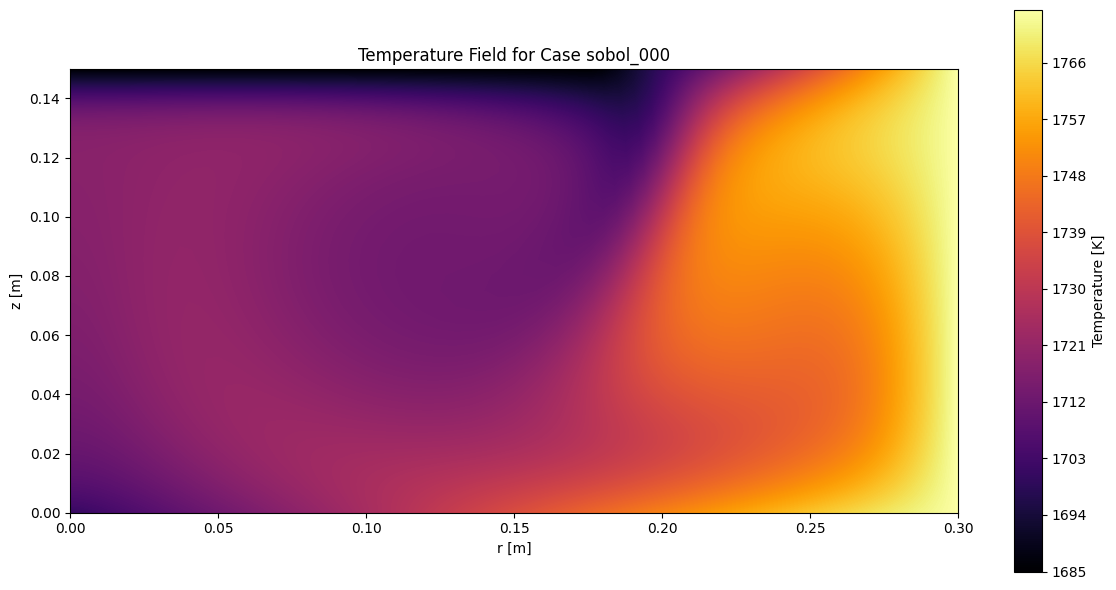

In [30]:
# tempeature field visualization

fig, ax = plt.subplots(figsize=(12, 6))

contour = ax.contourf(
    R, Z, T, levels=1000, cmap="inferno"
)

fig.colorbar(contour, ax=ax, label="Temperature [K]")

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Temperature Field for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

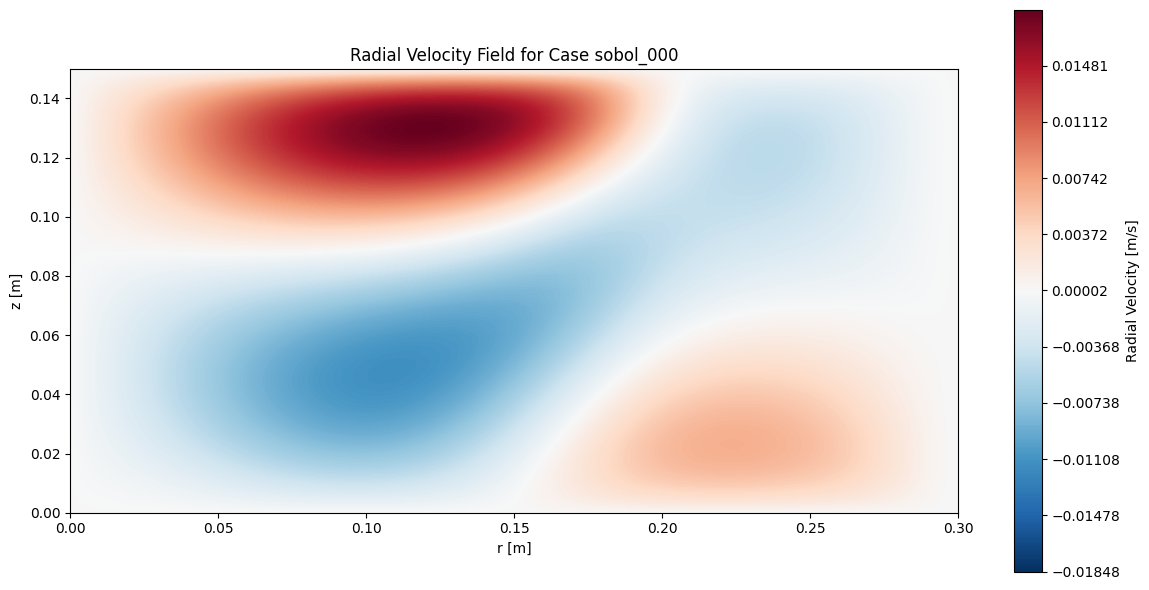

In [34]:
# Radial Velocity Field Visualization

fig, ax = plt.subplots(figsize=(12, 6))

vmax = np.abs(U_r).max()

contour = ax.contourf(
    R, Z, U_r, levels=np.linspace(-vmax, vmax, 1000), cmap="RdBu_r"
)

fig.colorbar(contour, ax=ax, label="Radial Velocity [m/s]")

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Radial Velocity Field for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()



In [37]:
# Generic scalar field visualization function

def plot_field(field,
               title,
               unit,
               cmap="RdBu_r",
               symmetric=False):

    fig, ax = plt.subplots(figsize=(12, 6))

    if symmetric:
        vmax = np.abs(field).max()
        levels = np.linspace(-vmax, vmax, 51)
    else:
        levels = 50

    contour = ax.contourf(
        R, Z, field, levels=levels, cmap=cmap
    )

    fig.colorbar(contour, ax=ax, label=unit)

    ax.set_xlabel("r [m]")
    ax.set_ylabel("z [m]")
    ax.set_title(title)
    ax.set_aspect("equal")

    plt.tight_layout()
    plt.show()


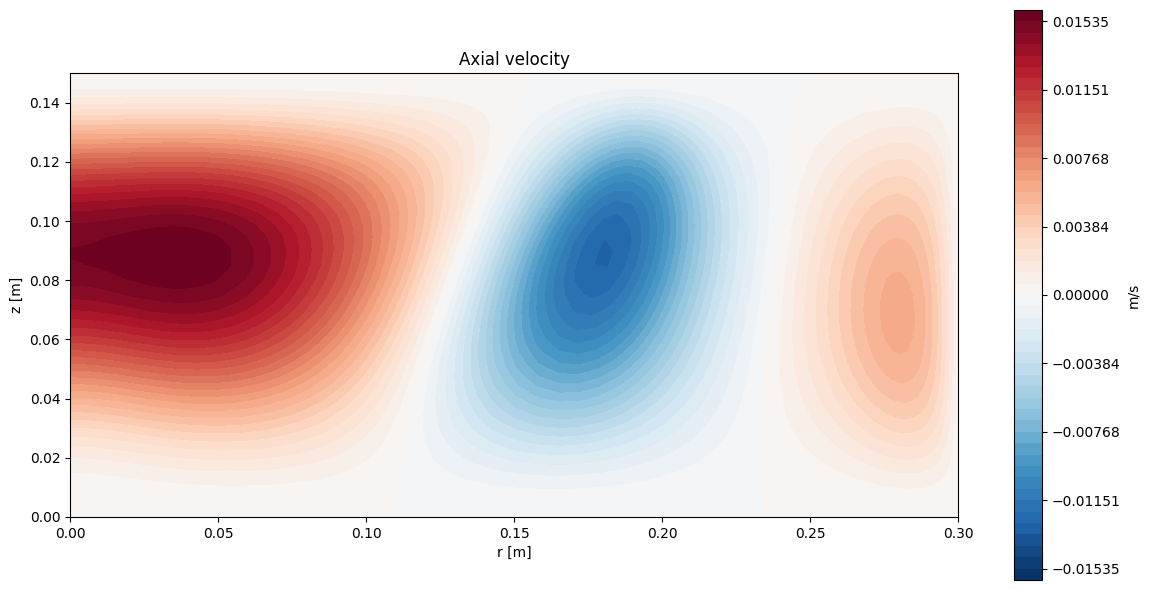

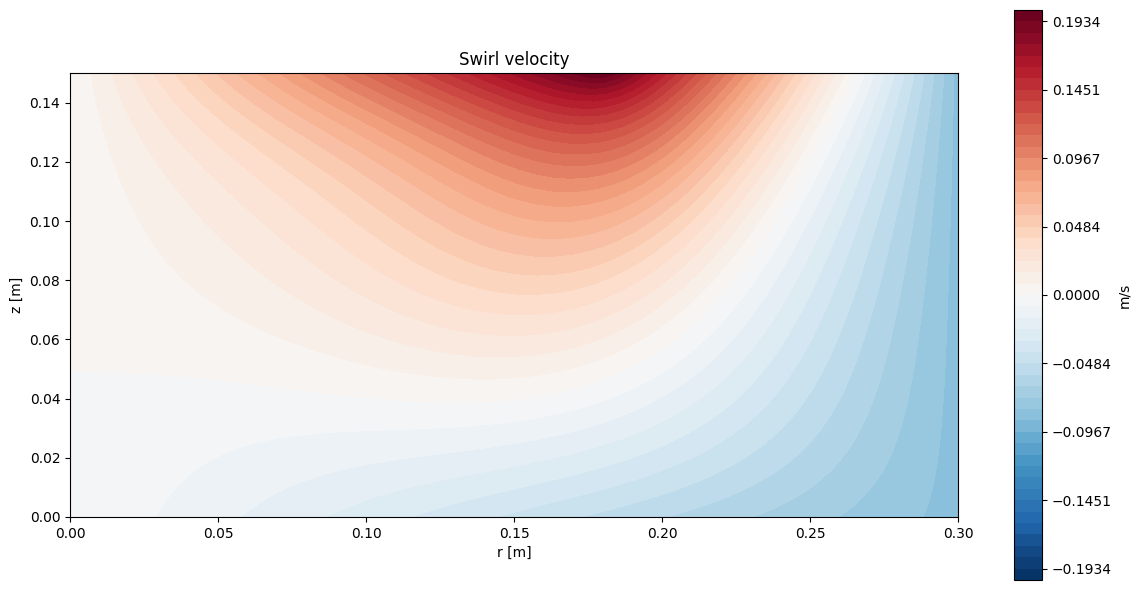

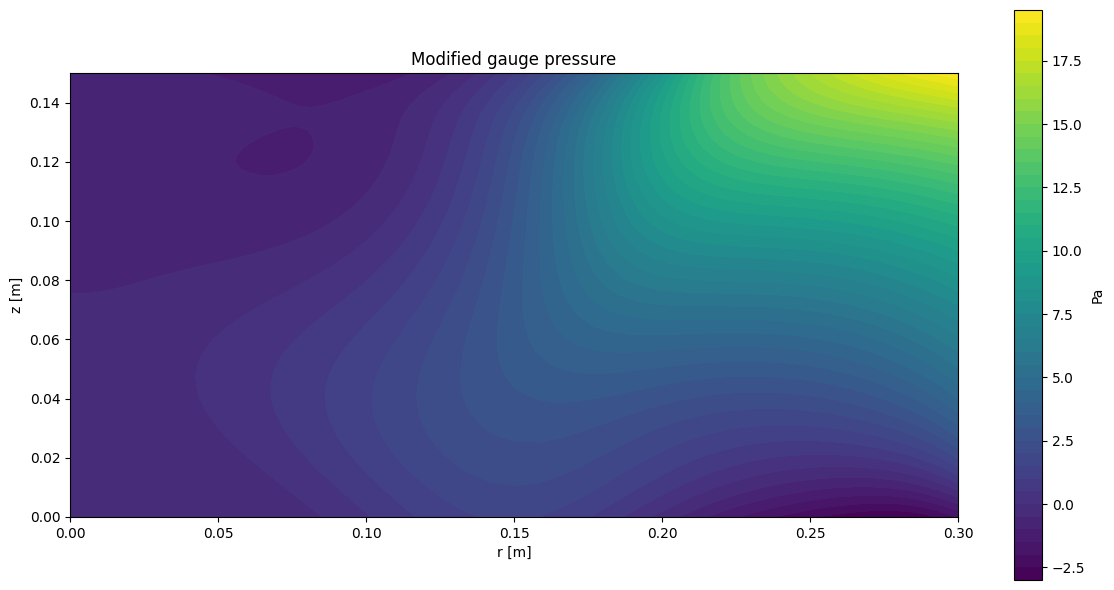

In [38]:
plot_field(
    U_z,
    "Axial velocity",
    "m/s",
    symmetric=True
)

plot_field(
    U_theta,
    "Swirl velocity",
    "m/s",
    symmetric=True
)

plot_field(
    P,
    "Modified gauge pressure",
    "Pa",
    cmap="viridis"
)

In [39]:
# Calculate velocity magnitudes

U_meriodinal = np.sqrt(U_r**2 + U_z**2)

U_total = np.sqrt(U_r**2 + U_z**2 + U_theta**2)

print("Maximum meridional velocity:", U_meriodinal.max())
print("Maximum total velocity:", U_total.max())

Maximum meridional velocity: 0.018631285221802747
Maximum total velocity: 0.2014794657


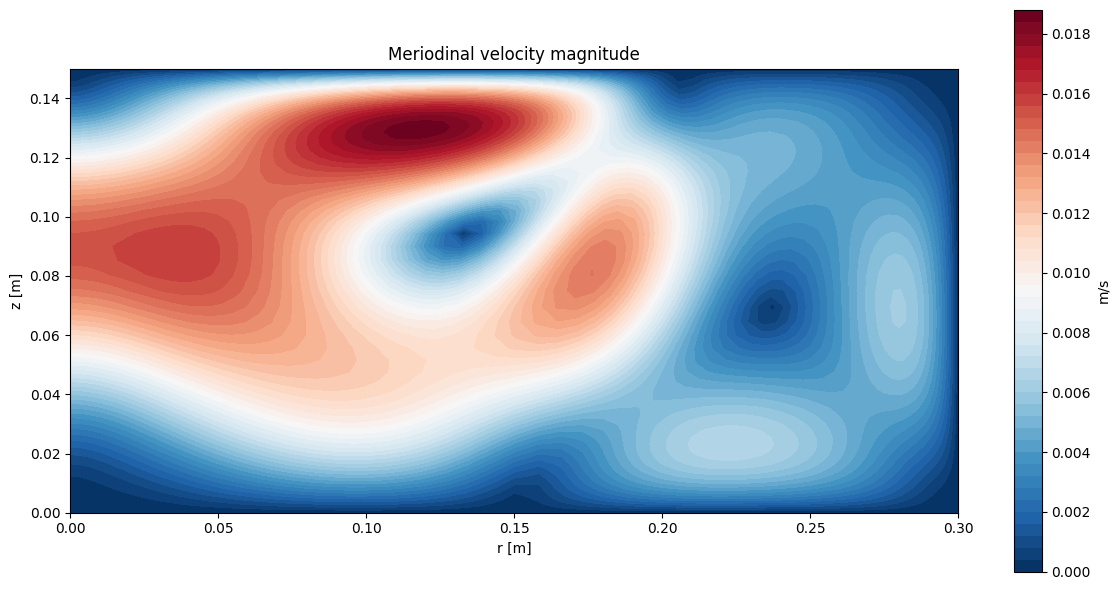

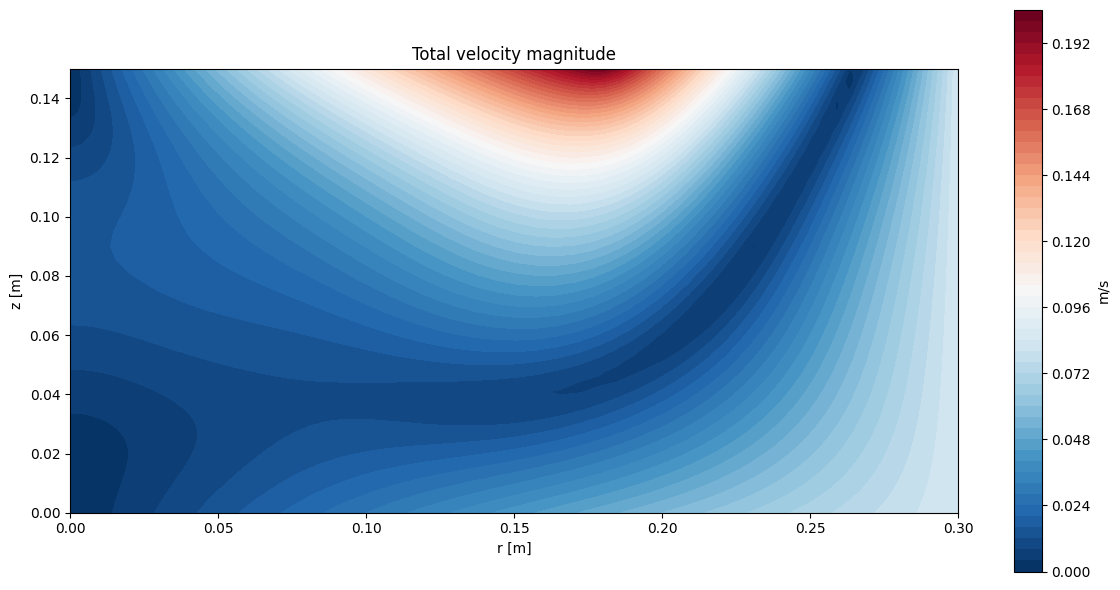

In [85]:
# Visualize velocity magnitudes

plot_field(
    U_meriodinal,
    "Meriodinal velocity magnitude",
    "m/s",
   # cmap="viridis"
)

plot_field(
    U_total,
    "Total velocity magnitude",
    "m/s",
    #cmap="viridis"
)

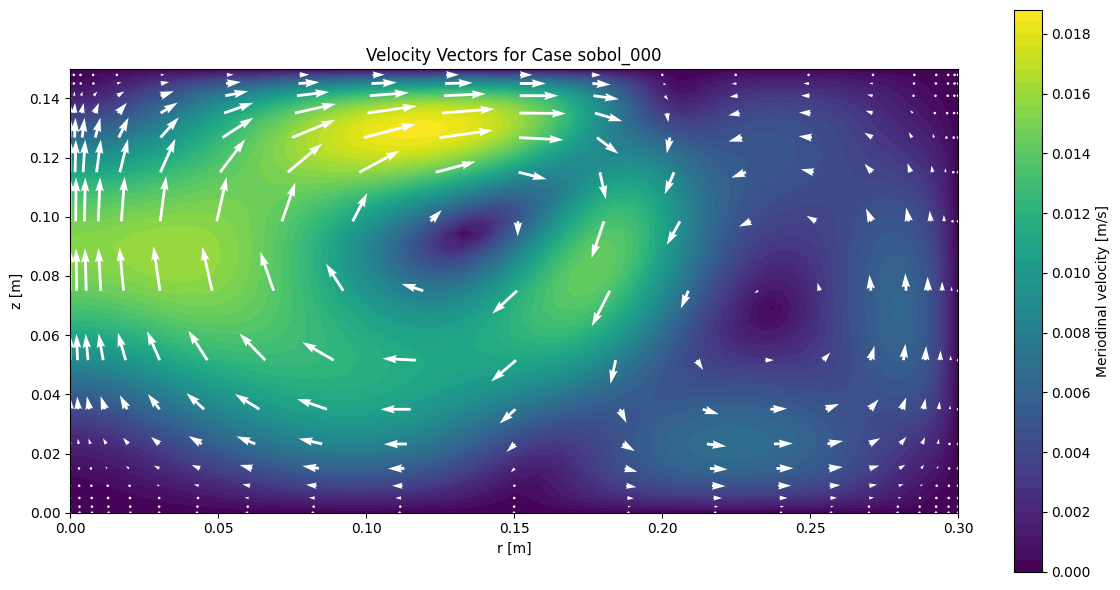

In [88]:
# Velocity vectors visualization

fig, ax = plt.subplots(figsize=(12, 6)) 

contour = ax.contourf(
    R, Z, U_meriodinal, levels=50, cmap="viridis"
)

step = 5

ax.quiver(
    R[::step, ::step],
    Z[::step, ::step],
    U_r[::step, ::step],
    U_z[::step, ::step],
    color="white",
    angles="xy",
    scale_units="xy",
    scale=1.0
)

fig.colorbar(
    contour, ax=ax, label="Meriodinal velocity [m/s]"
)

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Velocity Vectors for Case {case_id}")    
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Visulize melt ciculation with streamlinnes

In [51]:
# Interpolate on the uniform grid

from scipy.interpolate import griddata

r_uniform = np.linspace(
    df["r"].min(),
    df["r"].max(),
    220
)

z_uniform = np.linspace(
    df["z"].min(),
    df["z"].max(),
    110
)

R_uniform, Z_uniform = np.meshgrid(
    r_uniform,
    z_uniform
)

U_r_uniform = griddata(
    pos,
    df["u_r"].to_numpy(),
    (R_uniform, Z_uniform),
    method="linear"
)

U_z_uniform = griddata(
    pos,
    df["u_z"].to_numpy(),
    (R_uniform, Z_uniform),
    method="linear"
)

speed_uniform = np.hypot(
    U_r_uniform,
    U_z_uniform
)

print("Shape:", U_r_uniform.shape)
print("Missing values:", np.isnan(U_r_uniform).sum())



Shape: (110, 220)
Missing values: 0


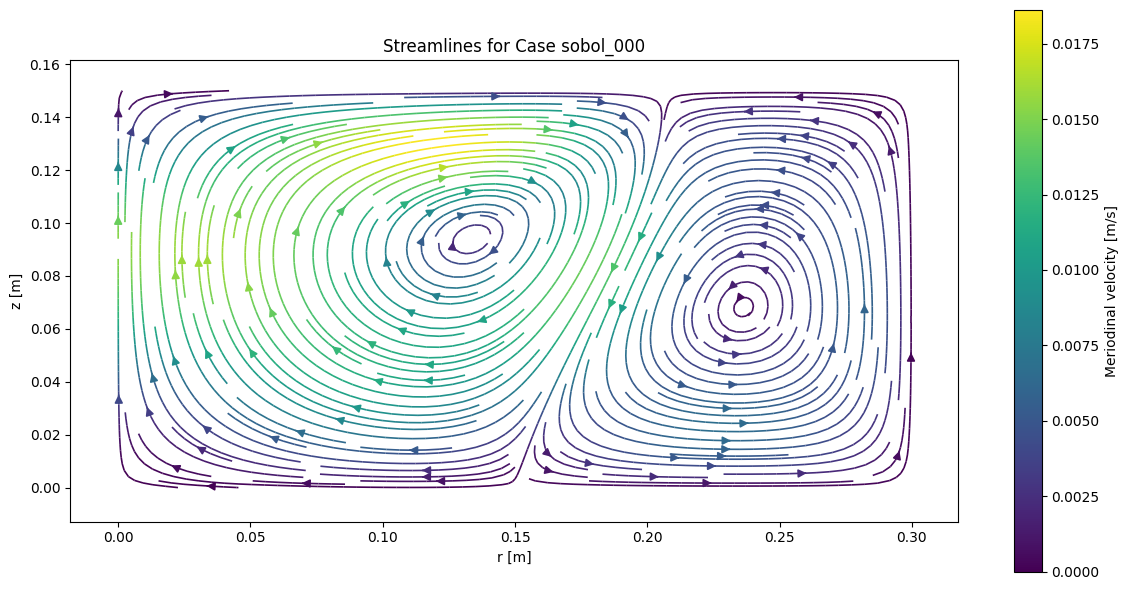

In [89]:
# PLot the streamlines

fig, ax = plt.subplots(figsize=(12, 6))

stream = ax.streamplot(
    R_uniform,
    Z_uniform,
    U_r_uniform,
    U_z_uniform,
    color=speed_uniform,
    cmap="viridis",
    density=2.0,
    linewidth=1.2,
    arrowsize=1.2
)

fig.colorbar(stream.lines, ax=ax, label="Meriodinal velocity [m/s]")
ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Streamlines for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Combine Temperature and velocity contours

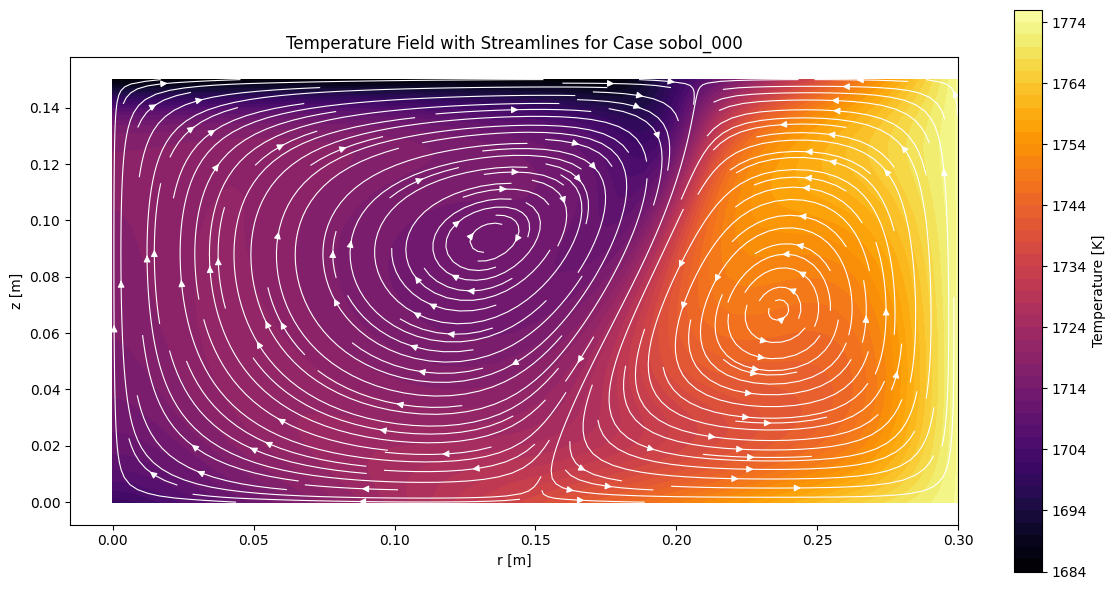

In [57]:
fig, ax = plt.subplots(figsize=(12, 6))

contour = ax.contourf(
    R, Z, T,
    levels=50,
    cmap="inferno"
)
ax.streamplot(
    r_uniform,
    z_uniform,
    U_r_uniform,
    U_z_uniform,
    color="white",
    density=1.8,
    linewidth=0.8,
    arrowsize=1.0
)

fig.colorbar(contour, ax=ax, label="Temperature [K]")

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Temperature Field with Streamlines for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Complete CFD Visualization

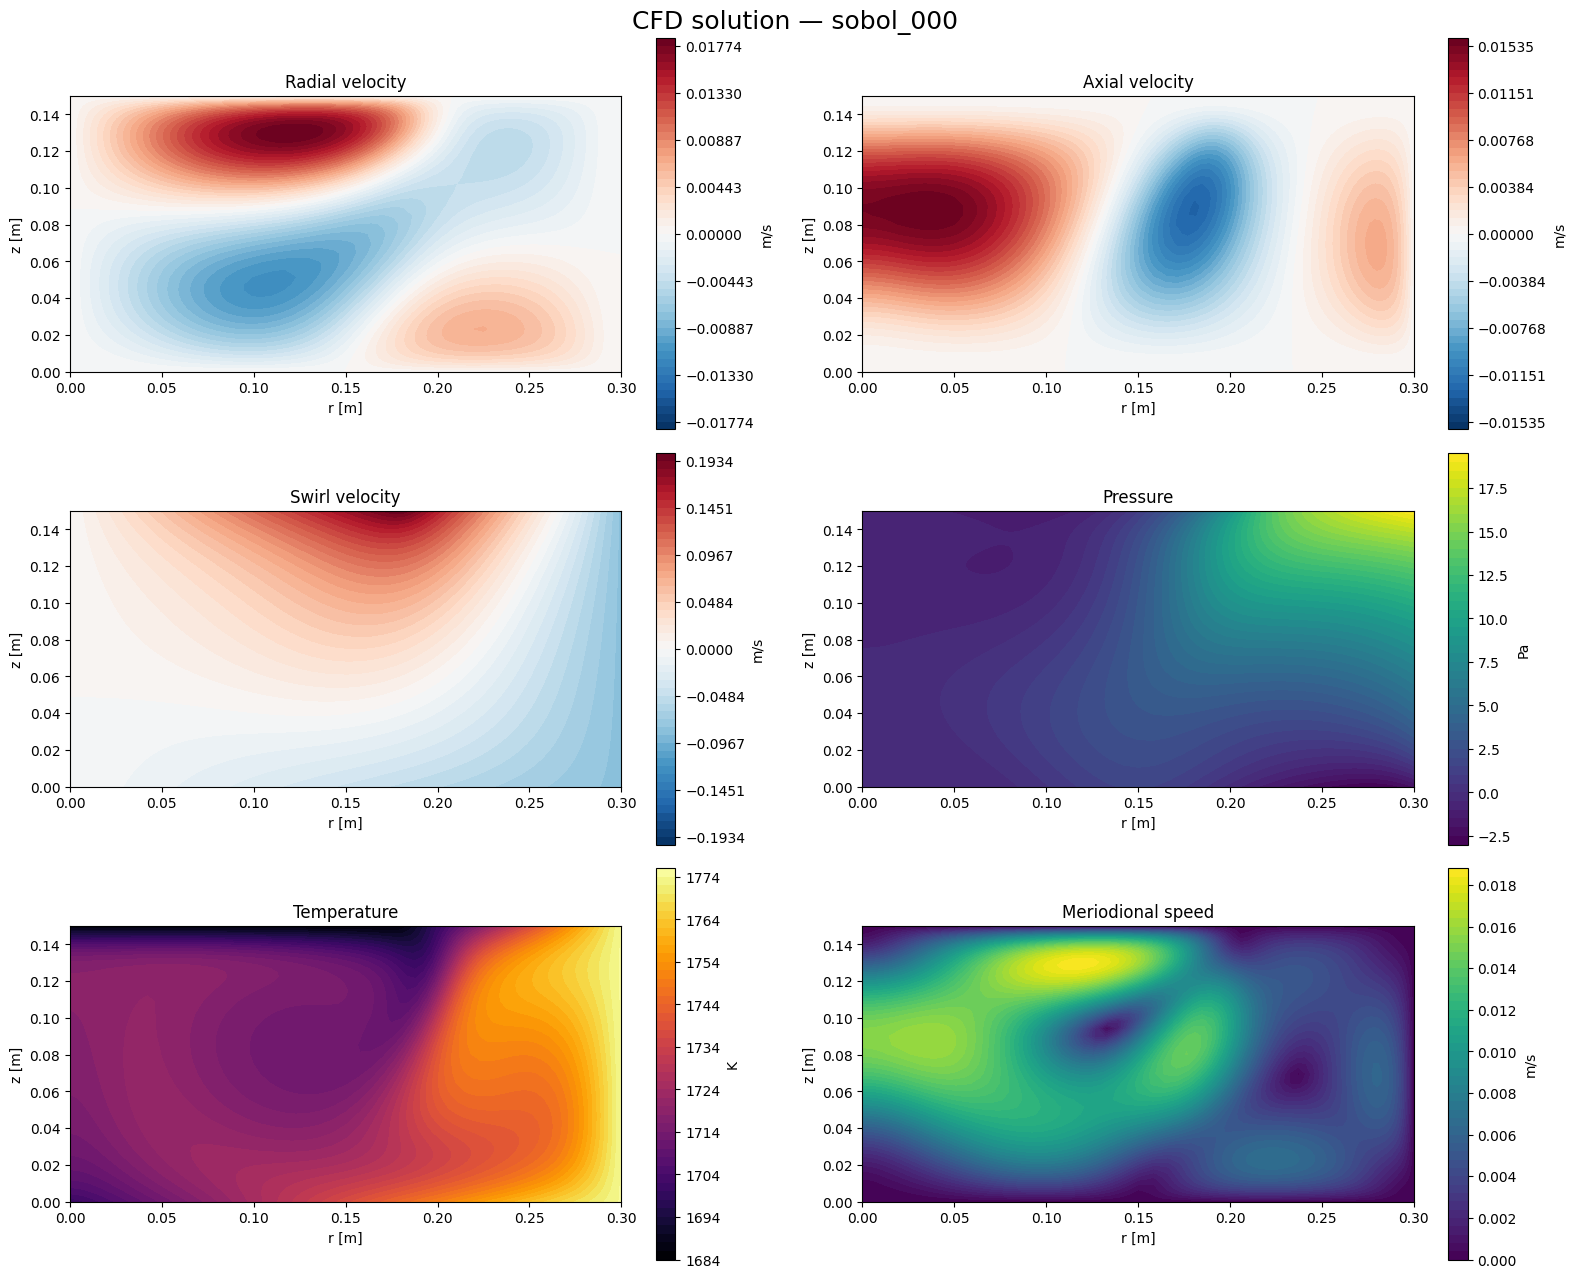

In [60]:
# Multi-field visualization

fields = [
    (U_r, "Radial velocity", "m/s", "RdBu_r", True),
    (U_z, "Axial velocity", "m/s", "RdBu_r", True),
    (U_theta, "Swirl velocity", "m/s", "RdBu_r", True),
    (P, "Pressure", "Pa", "viridis", False),
    (T, "Temperature", "K", "inferno", False),
    (U_meriodinal, "Meriodional speed", "m/s", "viridis", False)
]

fig, axes = plt.subplots(3, 2, figsize=(16, 13))

for ax, (field, title, unit, cmap, symmetric) in zip(
    axes.flat, fields
):

    if symmetric:
        vmax = np.abs(field).max()
        levels = np.linspace(-vmax, vmax, 51)
    else:
        levels = 50

    contour = ax.contourf(
        R, Z, field,
        levels=levels,
        cmap=cmap
    )

    fig.colorbar(contour, ax=ax, label=unit)

    ax.set_title(title)
    ax.set_xlabel("r [m]")
    ax.set_ylabel("z [m]")
    ax.set_aspect("equal")

fig.suptitle(f"CFD solution — {case_id}", fontsize=18)

plt.tight_layout()
plt.savefig(f"../figures/{case_id}_multi_field.png", dpi=300)
plt.show()

## Visualize the DOE parameter list

In [75]:
# Prepare case metadata

parameter_columns = [
    "crystal_rpm",
    "crucible_rpm",
    "t_hot"
]

metadata = cases.merge(
    status[["case_id", "status", "iterations"]],
    on="case_id",
    how="left",
    validate="one_to_one"
)

kept = metadata[metadata["status"] == "kept"].copy()
excluded = metadata[metadata["status"] == "excluded"].copy()

print("Total cases:", len(metadata))
print("Kept cases:", len(kept))
print("Excluded cases:", len(excluded))

Total cases: 265
Kept cases: 254
Excluded cases: 11


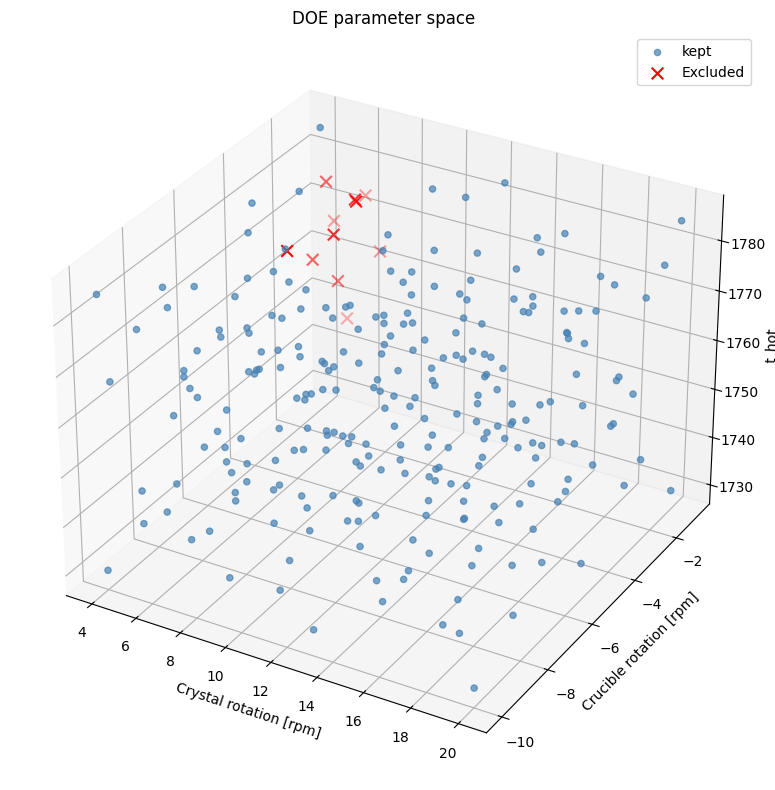

In [76]:
# Visualize the 3D parameter sapce

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    kept["crystal_rpm"],
    kept["crucible_rpm"],
    kept["t_hot"],
    c="steelblue",
    s=20,
    alpha=0.7,
    label="kept"
)

ax.scatter(
    excluded["crystal_rpm"],
    excluded["crucible_rpm"],
    excluded["t_hot"],
    c="red",
    marker='x',
    s=70,
    label="Excluded"
)

ax.set_xlabel("Crystal rotation [rpm]")
ax.set_ylabel("Crucible rotation [rpm]")
ax.set_zlabel("t_hot")

ax.set_title("DOE parameter space")
ax.legend()

plt.tight_layout()
plt.show()

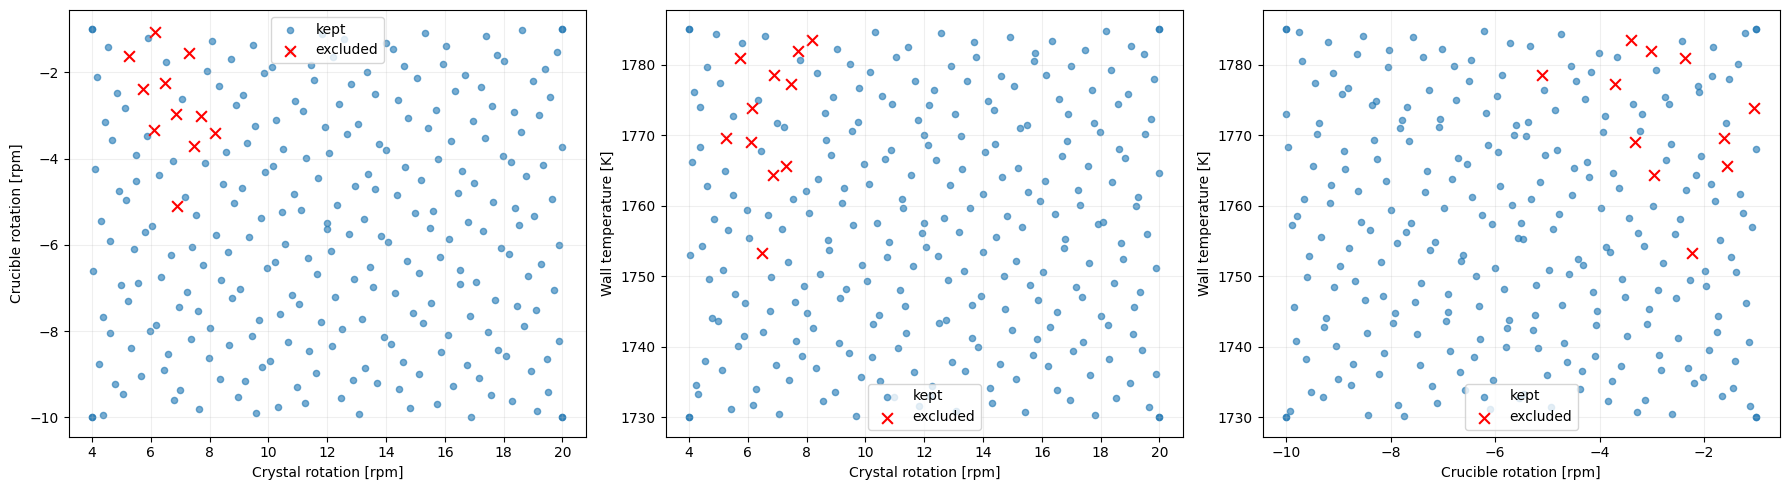

In [69]:
# Pairwise paramter-space coverage

pairs = [
    ("crystal_rpm", "crucible_rpm"),
    ("crystal_rpm", "t_hot"),
    ("crucible_rpm", "t_hot")
]

labels = {
    "crystal_rpm": "Crystal rotation [rpm]",
    "crucible_rpm": "Crucible rotation [rpm]",
    "t_hot": "Wall temperature [K]" 
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (xcol, ycol) in zip(axes, pairs):
    ax.scatter(
        kept[xcol],
        kept[ycol],
        s=20,
        alpha=0.6,
        label="kept"
    )

    ax.scatter(
        excluded[xcol],
        excluded[ycol],
        s=60,
        marker='x',
        color='red',
        label="excluded"
    )

    ax.set_xlabel(labels[xcol])
    ax.set_ylabel(labels[ycol])
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()


## Simulationn Loader

In [71]:
## Reusable Simulation loading funnction

def load_case(case_name):

    with zipfile.ZipFile(DOE_ZIP, "r") as archive:

        with archive.open(
            f"doe/{case_name}.csv"
        ) as file:
            data = pd.read_csv(file)

    info = metadata.set_index("case_id").loc[case_name]

    return data, info


In [77]:
data, info = load_case("corner_000")

print(data.shape)
print(info[parameter_columns])

(8181, 7)
crystal_rpm        4.0
crucible_rpm     -10.0
t_hot           1730.0
Name: corner_000, dtype: object


In [80]:
# Convert a case into a logical mesh

def get_case_grid(case_name):

    data, info = load_case(case_name)

    data = data.sort_values(
        ["z", "r"]
    ).reset_index(drop=True)

    nr = int(data.groupby("z").size().iloc[0])
    nz = data["z"].nunique()

    assert nr * nz == len(data)
    assert (data.groupby("z").size() == nr).all()

    grid = {}

    for col in data.columns:
        grid[col] = data[col].to_numpy().reshape(nr, nz)

    grid["U_meriodinal"] = np.hypot(
        grid["u_r"],
        grid["u_z"]
    )

    grid["U_total"] = np.sqrt(
        grid["u_r"]**2 +
        grid["u_z"]**2 +
        grid["u_swirl"]**2
    )

    return grid, info

## Comparative plotting funciton over cases

In [90]:
# compare a physical field across different cases

def compare_cases(case_names,
                  field,
                  cmap="veridis",
                  symmetric=False):

    results = [
        get_case_grid(name) for name in case_names
    ]

    vmin = min(grid[field].min() for grid, info in results)

    vmax = max(grid[field].max() for grid, info in results)

    if symmetric:
        limit = max(abs(vmin), abs(vmax))
        vmin, vmax = -limit, limit 

    levels = np.linspace(vmin, vmax, 51)

    n = len(case_names)

    fig, axes = plt.subplots(
        1, n,
        figsize=(7 * n, 5),
        constrained_layout=True
    )

    axes = np.atleast_1d(axes)

    for ax, name, (grid, info) in zip(
        axes, case_names, results
    ):
        contour = ax.contourf(
            grid["r"],
            grid["z"],
            grid[field],
            levels=levels,
            cmap=cmap

        )
        ax.set_title(
            f"{name}\n"
            f"Crystal = {info["crystal_rpm"]:.1f} rpm\n"
            f"Crusible = {info["crucible_rpm"]:.1f} rpm\n"
            f"T_hot = {info["t_hot"]:.1f} K"
        )

        ax.set_xlabel("r [m]")
        ax.set_ylabel("z [m]")
        ax.set_aspect("equal")

    units = {
        "T": "K",
        "p": "Pa",
        "u_r": "m/s",
        "u_z": "m/s",
        "u_swirl": "m/s",
        "U_meriodinal": "m/s",
        "U_total": "m/s"
    }

    fig.colorbar(
        contour,
        ax=axes.tolist(),
        label=f"{field} [{units[field]}]",
        shrink=0.8
    )

    plt.show()

### Compare low and high crystal rotation

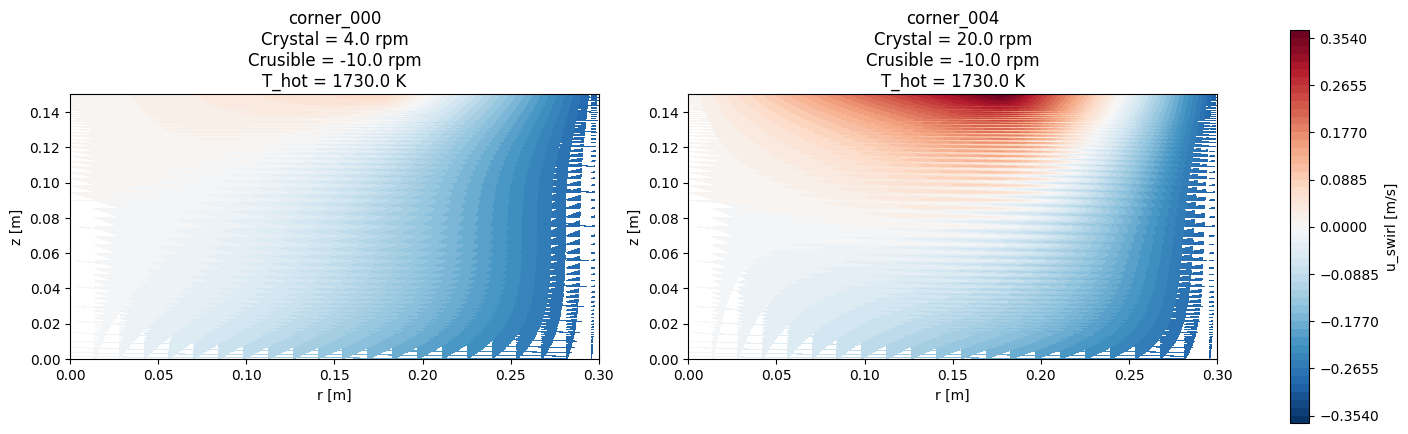

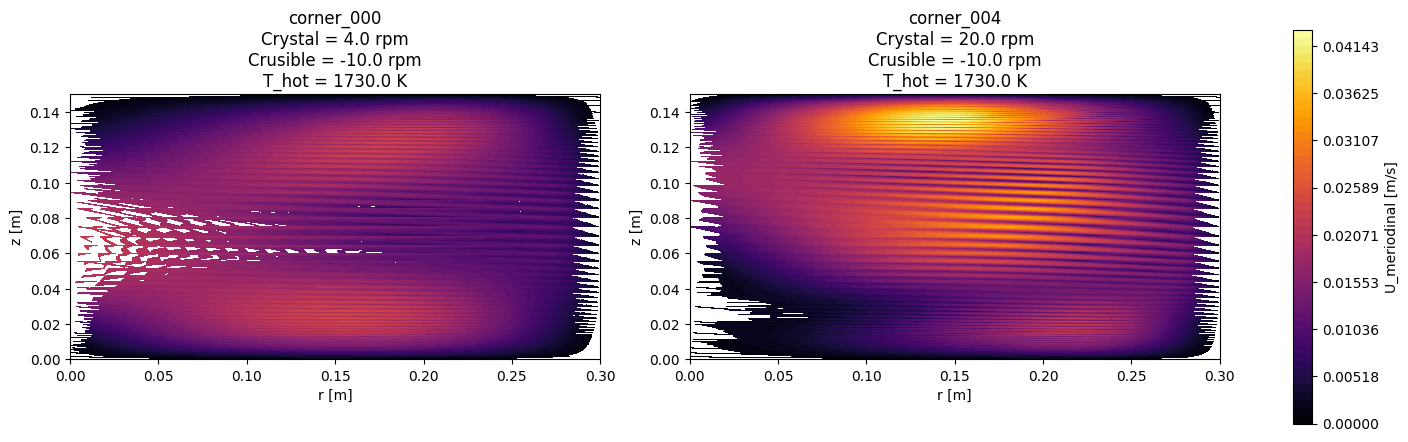

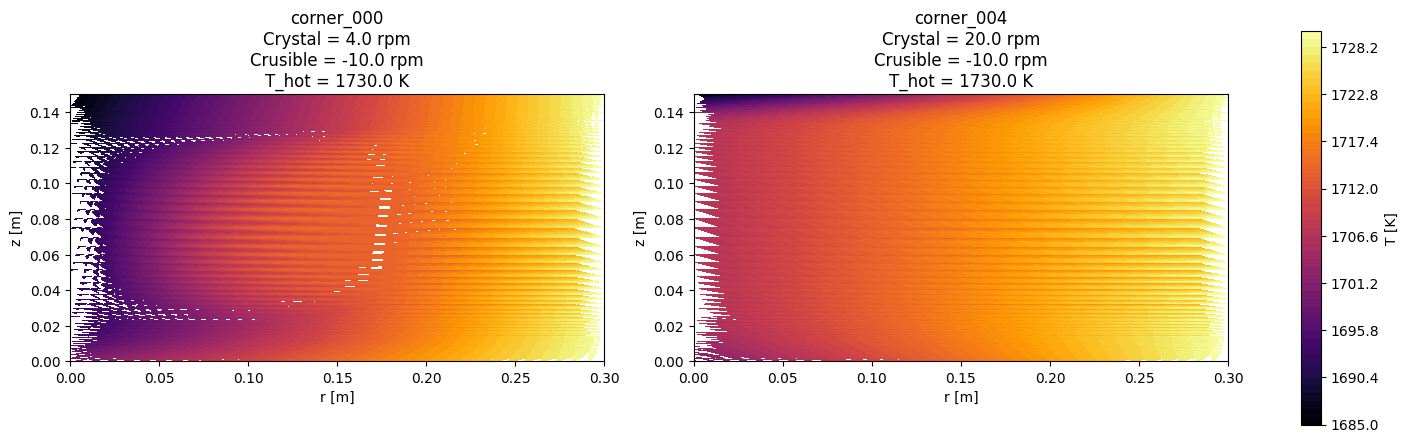

In [93]:
crystal_cases = [
    "corner_000",
    "corner_004"
]

compare_cases(
    crystal_cases,
    "u_swirl",
    cmap="RdBu_r",
    symmetric=True
)

compare_cases(
    crystal_cases,
    "U_meriodinal",
    cmap="inferno"
)

compare_cases(
    crystal_cases,
    "T",
    cmap="inferno"
)